# Dự án: phân tích và dự đoán Telco Customer Churn

Mục tiêu: thực hành dữ liệu dạng bảng với Pandas và scikit-learn. Nhãn `Churn` bằng Yes nếu khách hàng rời dịch vụ trong tháng gần nhất. Đọc [PLAN.md](PLAN.md) để xem kế hoạch và [README.md](README.md) để chạy lại.

Dữ liệu: [Kaggle — Telco Customer Churn](https://www.kaggle.com/datasets/blastchar/telco-customer-churn). File `data/source.json` ghi nguồn tải thực tế và checksum.

In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
from IPython.display import display, Image, Markdown

ROOT = Path.cwd()
if not (ROOT / 'telco_churn.py').exists():
    ROOT = ROOT / 'telco-churn'
sys.path.insert(0, str(ROOT))
from telco_churn import load_data, run_project, NUMERIC, CATEGORICAL
from download_data import download
download()
print('Project:', ROOT)

Using existing file: D:\Downloads\AI Engineer\AI1\telco-churn\data\WA_Fn-UseC_-Telco-Customer-Churn.csv
Project: D:\Downloads\AI Engineer\AI1\telco-churn


## 1. Đọc và kiểm tra dữ liệu

Mỗi dòng là một khách hàng. `customerID` chỉ là mã, không dùng làm đầu vào. `Churn` là nhãn và phải bỏ khỏi đặc trưng để mô hình không nhìn trước đáp án.

In [2]:
raw, X, y, audit = load_data()
display(raw.head())
display(pd.DataFrame({'dtype': raw.dtypes.astype(str), 'missing_raw': raw.isna().sum()}))
print(json.dumps(audit, indent=2, ensure_ascii=False))

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


,dtype,missing_raw
customerID,str,0
gender,str,0
SeniorCitizen,int64,0
Partner,str,0
Dependents,str,0
tenure,int64,0
PhoneService,str,0
MultipleLines,str,0
InternetService,str,0
OnlineSecurity,str,0


{
  "rows": 7043,
  "raw_columns": 21,
  "features": 19,
  "duplicate_customer_ids": 0,
  "missing_numeric": {
    "tenure": 0,
    "MonthlyCharges": 0,
    "TotalCharges": 11
  },
  "churn_counts": {
    "0": 5174,
    "1": 1869
  },
  "churn_rate": 0.2653698707936959
}


## 2. Làm sạch và hiểu dữ liệu

`TotalCharges` có chuỗi trống, nên chuyển thành số rồi giữ NaN. Việc điền thiếu sẽ nằm trong pipeline và chỉ học trung vị từ train. `SeniorCitizen` là mã 0/1; xử lý như cột phân loại. Những giá trị như `No internet service` là nhóm hợp lệ, không phải dữ liệu thiếu.

In [3]:
display(X[NUMERIC].describe())
print('Số giá trị thiếu sau chuyển đổi:')
display(X.isna().sum().loc[lambda s: s > 0])
print('Tỷ lệ nhãn:')
display(y.value_counts(normalize=True).rename(index={0: 'No churn', 1: 'Churn'}))
display(raw.assign(churn_flag=y).groupby('Contract')['churn_flag'].agg(customers='size', churn_rate='mean'))

,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7032.000000
mean,32.371149,64.761692,2283.300441
std,24.559481,30.090047,2266.771362
min,0.000000,18.250000,18.800000
25%,9.000000,35.500000,401.450000
50%,29.000000,70.350000,1397.475000
75%,55.000000,89.850000,3794.737500
max,72.000000,118.750000,8684.800000


Số giá trị thiếu sau chuyển đổi:


TotalCharges    11
dtype: int64

Tỷ lệ nhãn:


Churn
No churn    0.73463
Churn       0.26537
Name: proportion, dtype: float64

,customers,churn_rate
Contract,,
Month-to-month,3875,0.427097
One year,1473,0.112695
Two year,1695,0.028319


## 3. Chia dữ liệu, huấn luyện và đánh giá

Chia 60/20/20 với stratification và seed 42. Train để học; validation để chọn mô hình/ngưỡng; test để đánh giá cuối. Chỉ fit imputer, scaler và encoder trên train.

So sánh baseline luôn dự đoán No, Logistic Regression và Random Forest. Chọn ngưỡng có F1 cao nhất trên validation, sau đó chọn mô hình có F1 validation cao nhất. Khóa lựa chọn trước khi đọc kết quả test. Không refit trên validation để tránh thay đổi mô hình đã chọn.

Mã pipeline đầy đủ trong `telco_churn.py`: đọc các hàm `make_pipeline`, `metrics_for` và `run_project` để hiểu từng bước.

In [4]:
results = run_project(ROOT)
print('Số dòng từng tập:', results['split_sizes'])
print('Mô hình được chọn:', results['selected_model'])
print('Ngưỡng được chọn:', results['threshold'])
print('VALIDATION')
display(pd.DataFrame(results['validation']).round(4))
print('TEST')
display(pd.DataFrame(results['test']).round(4))

Training Baseline_NoChurn ...


Training LogisticRegression ...


Training RandomForest ...


Locked selection from validation: LogisticRegression


             model  threshold  accuracy  precision  recall     f1  roc_auc  average_precision
  Baseline_NoChurn       0.50    0.7346     0.0000  0.0000 0.0000   0.5000             0.2654
LogisticRegression       0.37    0.7693     0.5525  0.6898 0.6136   0.8429             0.6342
      RandomForest       0.46    0.7622     0.5385  0.7299 0.6198   0.8373             0.6394


Số dòng từng tập: {'train': 4225, 'validation': 1409, 'test': 1409}
Mô hình được chọn: LogisticRegression
Ngưỡng được chọn: 0.37
VALIDATION


,model,threshold,accuracy,precision,recall,f1,roc_auc,average_precision
0,Baseline_NoChurn,0.50,0.7346,0.0000,0.0000,0.0000,0.5000,0.2654
1,LogisticRegression,0.37,0.7871,0.5849,0.6818,0.6296,0.8360,0.6424
2,RandomForest,0.46,0.7672,0.5464,0.7246,0.6230,0.8294,0.6223


TEST


,model,threshold,accuracy,precision,recall,f1,roc_auc,average_precision
0,Baseline_NoChurn,0.50,0.7346,0.0000,0.0000,0.0000,0.5000,0.2654
1,LogisticRegression,0.37,0.7693,0.5525,0.6898,0.6136,0.8429,0.6342
2,RandomForest,0.46,0.7622,0.5385,0.7299,0.6198,0.8373,0.6394


## 4. Đọc biểu đồ và kết quả

Precision cho biết độ tin cậy của cảnh báo; recall cho biết phát hiện được bao nhiêu khách hàng churn; F1 cân bằng precision và recall. Accuracy cần so sánh với baseline vì nhãn mất cân bằng. ROC-AUC và AP dùng xác suất thay vì một ngưỡng duy nhất.

Ma trận nhầm lẫn: hàng là nhãn thật, cột là dự đoán. Cảnh báo nhầm và bỏ sót đều có chi phí; tối ưu F1 chỉ là lựa chọn ban đầu cho bài học.

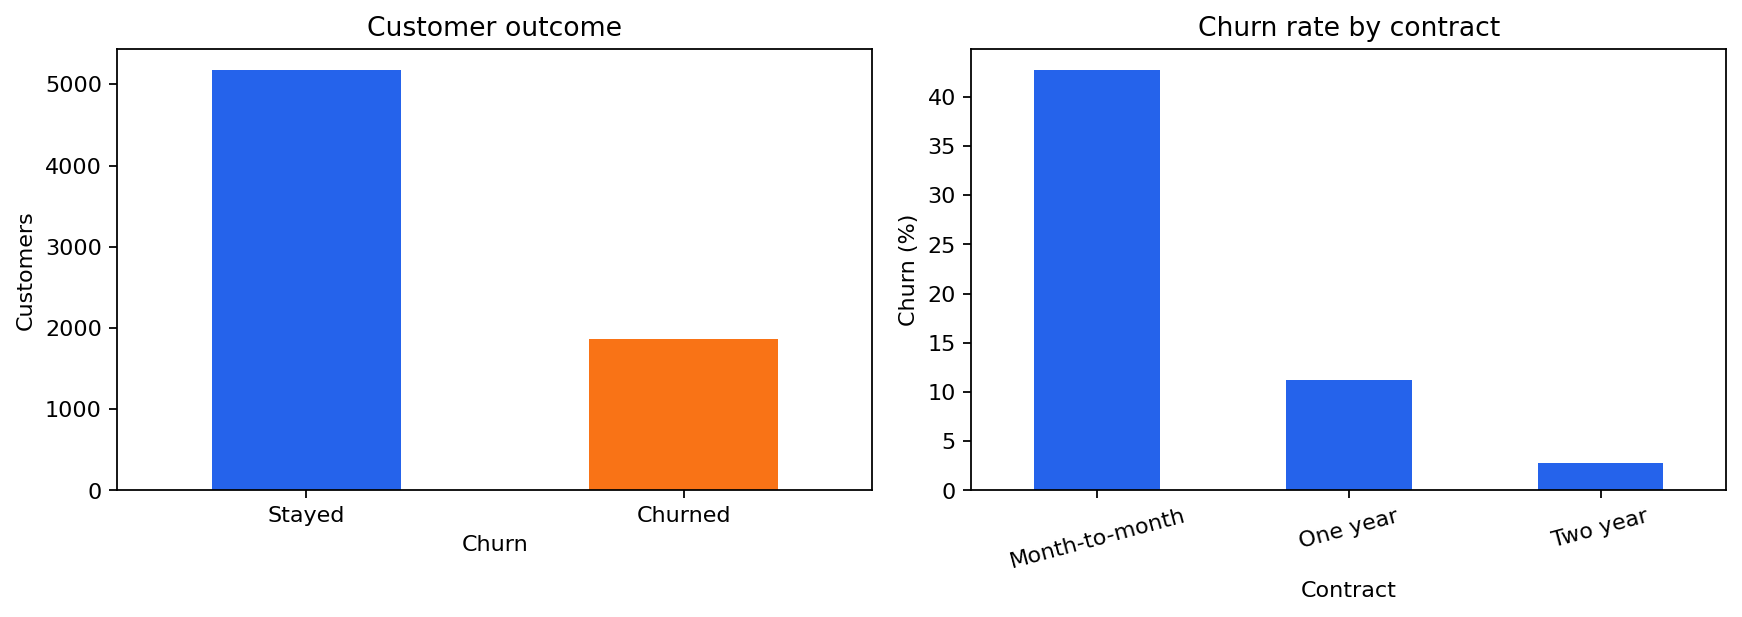

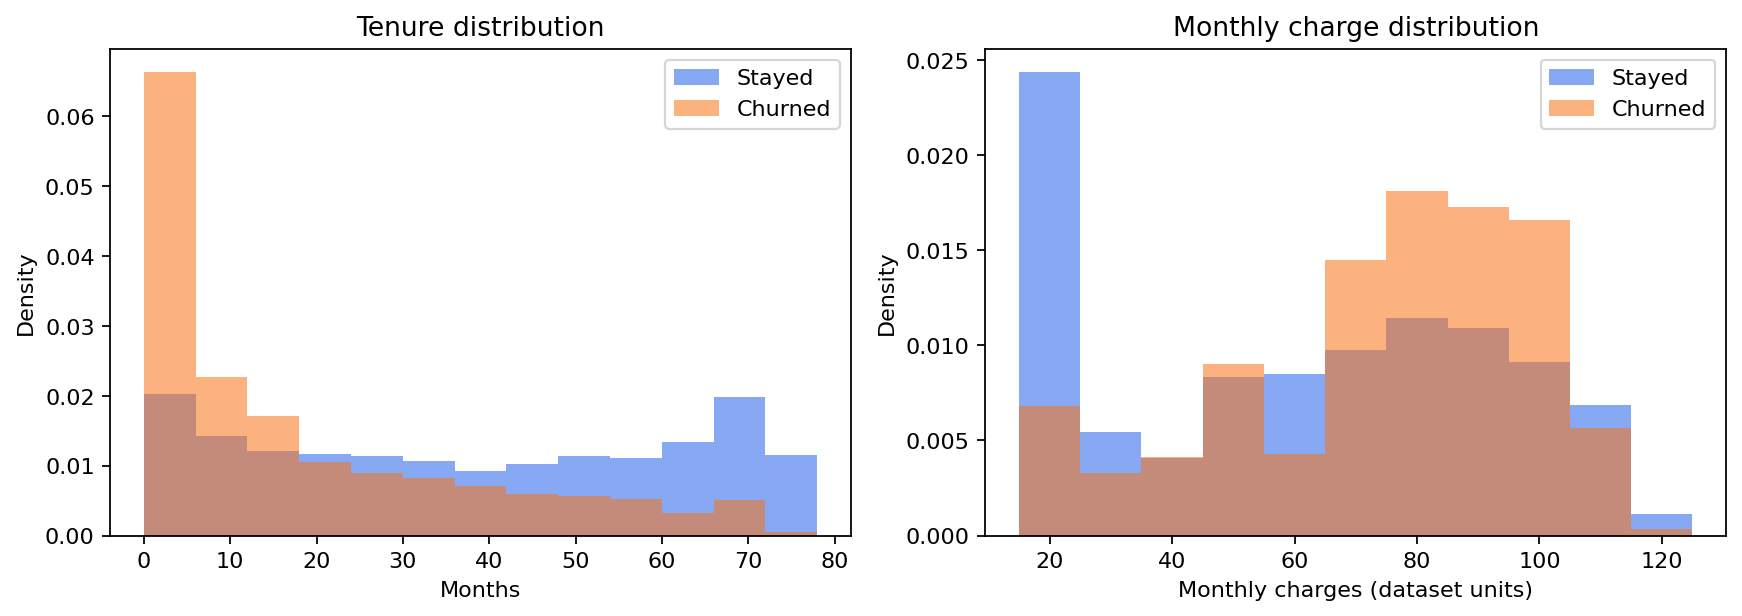

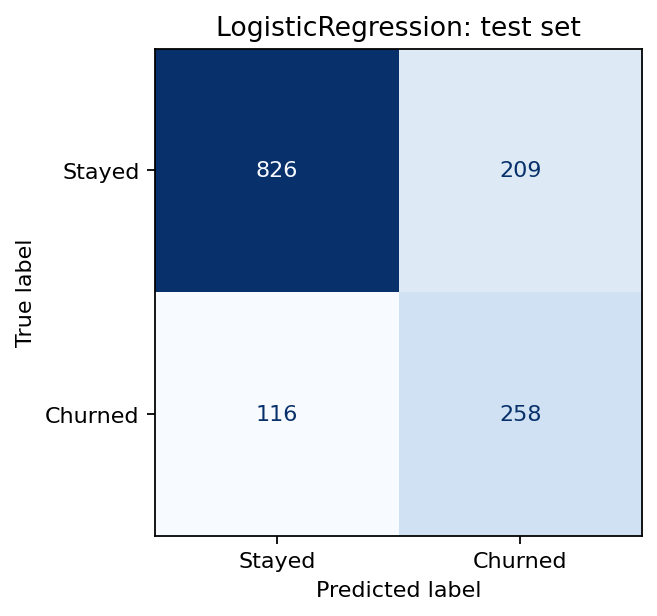

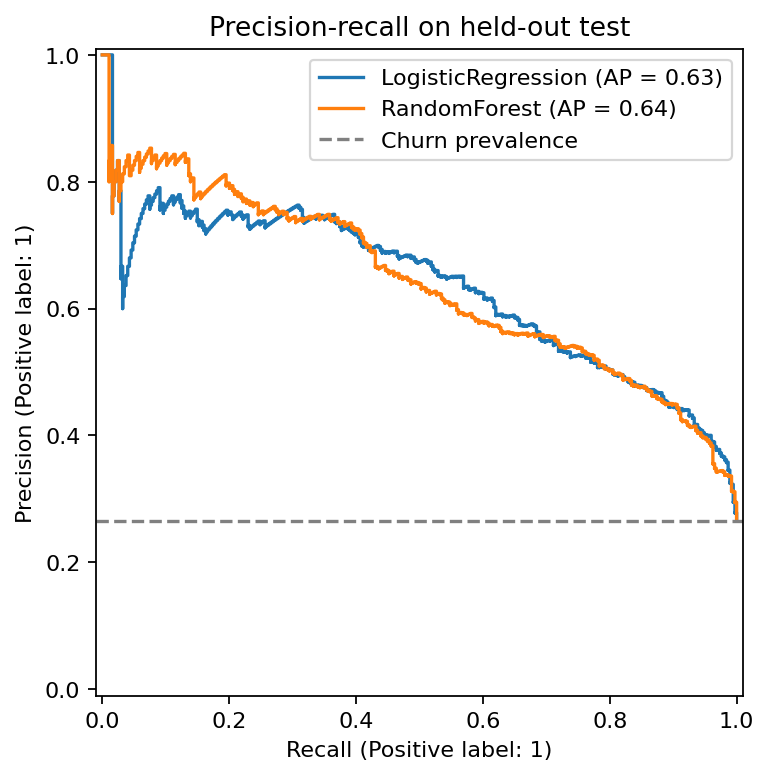

In [5]:
for filename in ['01_churn_and_contract.png', '02_tenure_and_charges.png', '03_confusion_matrix.png', '04_precision_recall.png']:
    display(Image(filename=str(ROOT / 'reports' / 'figures' / filename)))

## 5. Dự đoán từ pipeline đã lưu

Ví dụ dưới đây dùng ba dòng của tập test để kiểm tra cách nạp mô hình; đây không phải khách hàng mới. Mô hình dùng đúng preprocessing và ngưỡng đã khóa. Với CSV của bạn, chạy:

```powershell
python predict.py --input du_lieu_moi.csv --output du_doan.csv
```

CSV cần đủ 19 cột đặc trưng. `customerID` và `Churn` không dùng làm đầu vào mô hình.

In [6]:
from predict import predict
held_out_ids = pd.read_csv(ROOT / 'reports' / 'splits.csv').query("split == 'test'")['customerID'].head(3)
example = raw.set_index('customerID').loc[held_out_ids].reset_index().drop(columns='Churn')
example.to_csv(ROOT / 'data' / 'example_customers.csv', index=False)
display(predict(ROOT / 'data' / 'example_customers.csv', ROOT / 'reports' / 'example_predictions.csv'))

,customerID,churn_probability,predicted_churn
0,4376-KFVRS,0.039281,0
1,2754-SDJRD,0.702656,1
2,9917-KWRBE,0.059786,0


## 6. Kết luận và giới hạn

Đọc báo cáo đã sinh để lấy số liệu và kết luận thực tế. Dữ liệu mẫu không xác nhận hiệu quả triển khai; không có mốc thời gian để kiểm tra khả năng dự báo tương lai. Quan hệ giữa hợp đồng/chi phí và churn không chứng minh nguyên nhân. Xác suất chưa được hiệu chỉnh calibration.

Bài tập mở rộng: thử validation chéo trên train, chọn ngưỡng theo chi phí, hoặc thử mô hình khác. Khi phát triển nhiều vòng, cần một test mới; tránh chỉnh mô hình dựa trên test hiện tại.

In [7]:
report = (ROOT / 'reports' / 'REPORT.md').read_text(encoding='utf-8')
display(Markdown(report.replace('(figures/', '(reports/figures/')))

# Báo cáo Telco Customer Churn

## Dữ liệu và mục tiêu

Phân loại nhãn `Churn = Yes/No` của khách hàng viễn thông. Nhãn cho biết khách hàng đã rời dịch vụ trong tháng gần nhất; đây là bài thực hành phân loại trên dữ liệu mẫu, chưa chứng minh khả năng dự báo tương lai.

- Nguồn thực tế: Kaggle / BlastChar — https://www.kaggle.com/api/v1/datasets/download/blastchar/telco-customer-churn
- Trang Kaggle: https://www.kaggle.com/datasets/blastchar/telco-customer-churn
- SHA-256: `88be4b93fbe0cc83421af1c503794c97c342eca914c1576db7c276e61d61358a`
- 7,043 dòng, 21 cột gốc; dùng 19 đặc trưng sau khi bỏ `customerID` và `Churn`.
- Tỷ lệ churn: 26.54%; mã khách hàng trùng: 0.
- `TotalCharges`: 11 giá trị thiếu sau chuyển số; điền bằng trung vị học từ train.

## Phân tích mô tả

- Month-to-month: 3,875 khách hàng, tỷ lệ churn 42.7%.
- One year: 1,473 khách hàng, tỷ lệ churn 11.3%.
- Two year: 1,695 khách hàng, tỷ lệ churn 2.8%.

![Churn và hợp đồng](reports/figures/01_churn_and_contract.png)

![Thời gian sử dụng và chi phí](reports/figures/02_tenure_and_charges.png)

Các biểu đồ dùng toàn bộ dữ liệu cho mô tả. Chúng thể hiện liên hệ, không xác lập nguyên nhân khách hàng rời đi.

## Phương pháp

Chia stratified với seed 42: train 4,225, validation 1,409, test 1,409. Các tập không trùng khách hàng. Điền thiếu, chuẩn hóa số và one-hot encoding được fit chỉ trên train, giữ nguyên khi xử lý validation/test.

Baseline luôn dự đoán không churn. Logistic Regression (`max_iter=2000`) và Random Forest (300 cây, `min_samples_leaf=3`, `class_weight=balanced_subsample`) dùng cùng dữ liệu train. Tìm ngưỡng từ 0,10 đến 0,80, bước 0,01, bằng F1 validation; nếu hòa, ưu tiên gần 0,50. Chọn mô hình chỉ bằng F1 validation, không thay đổi lựa chọn theo test. Không refit bằng validation để giữ đúng mô hình và ngưỡng đã đánh giá.

### Kết quả validation

- Baseline_NoChurn: F1 = 0.000; ngưỡng = 0.50.
- LogisticRegression: F1 = 0.630; ngưỡng = 0.37.
- RandomForest: F1 = 0.623; ngưỡng = 0.46.

Mô hình được chọn: **LogisticRegression**.

### Kết quả test

| Mô hình | Ngưỡng | Accuracy | Precision | Recall | F1 | ROC-AUC | AP |
|---|---:|---:|---:|---:|---:|---:|---:|
| Baseline_NoChurn | 0.50 | 0.735 | 0.000 | 0.000 | 0.000 | 0.500 | 0.265 |
| LogisticRegression | 0.37 | 0.769 | 0.552 | 0.690 | 0.614 | 0.843 | 0.634 |
| RandomForest | 0.46 | 0.762 | 0.538 | 0.730 | 0.620 | 0.837 | 0.639 |


Accuracy có thể cao dù mô hình bỏ sót mọi ca churn, vì đa số khách hàng không churn. Precision là tỷ lệ churn thật trong nhóm bị cảnh báo; recall là tỷ lệ ca churn mô hình phát hiện được; F1 cân bằng hai giá trị này. AP tóm tắt đường precision–recall, baseline xấp xỉ tỷ lệ churn.

Mô hình được chọn: recall 69.0%, precision 55.2%, F1 0.614. Ma trận nhầm lẫn: TN=826, FP=209, FN=116, TP=258; còn bỏ sót 116 khách hàng churn và cảnh báo nhầm 209 khách hàng ở lại.

![Ma trận nhầm lẫn](reports/figures/03_confusion_matrix.png)

![Precision recall](reports/figures/04_precision_recall.png)

## Cách sử dụng và giới hạn

`models/churn_pipeline.joblib` chứa preprocessing và classifier; `models/model_metadata.json` chứa ngưỡng và schema. Chạy `python predict.py --input du_lieu_moi.csv --output du_doan.csv` với CSV có đủ 19 cột đặc trưng. Kết quả gồm xác suất và nhãn suy luận; xác suất chưa được hiệu chỉnh calibration.

Đây là dữ liệu mẫu cho học tập, không phải đánh giá trên khách hàng của doanh nghiệp đang hoạt động. Dữ liệu không có mốc thời gian để chia theo thời gian hoặc biết chính xác đặc trưng được ghi trước churn. Chỉ cân nhắc vận hành sau khi có dữ liệu thực tế, định nghĩa cửa sổ dự báo, kiểm tra theo thời gian và chi phí cảnh báo/bỏ sót. Chưa có thử nghiệm cho thấy việc giữ chân dựa trên mô hình làm giảm churn.
